# MapleFreight Logistics — Delivery Delay Prediction & Slack Alerts

**AML 3303 · Assessment 1** · Author: Arti · Student ID: `<your_id>`

This notebook builds an early-warning system for late deliveries. It cleans the raw shipment export, finds what drives late delivery, trains and evaluates a classifier that flags shipments likely to miss their promised window, explains each alert, and posts the highest-risk shipments to the `#dispatch-alerts` Slack channel.

| # | Section |
|---|---|
| 1 | Context, problem statement and objectives |
| 2 | Setup |
| 3 | Data understanding |
| 4 | Data preprocessing |
| 5 | Exploratory data analysis |
| 6 | Feature engineering |
| 7 | Data preparation |
| 8 | Data modelling |
| 9 | Model evaluation and alert threshold |
| 10 | Model explainability |
| 11 | Slack alert integration |
| 12 | Recommendations |
| 13 | Limitations and next steps |

## 1. Context, problem statement and objectives

**Context.** MapleFreight moves about 8,000 shipments a week across Ontario, Quebec and the Prairies. Contracts carry on-time guarantees, so every late delivery costs a service credit and often a re-delivery. On-time performance has fallen from 94% to 88% this year.

**Problem.** Today a late shipment is discovered only when the customer calls, after the delivery window has passed. By then the credit is owed and the complaint has reached the account manager before dispatch knows anything is wrong.

**Objectives.**
1. Identify the main drivers of late delivery from shipment, route and carrier data.
2. Build a classifier that predicts, at dispatch, whether a shipment will be delivered late.
3. Send dispatch an automatic Slack alert listing the highest-risk shipments while there is still time to re-route or warn the customer.
4. Turn the findings into actions that improve on-time performance.

**Success criteria.** Because 21% of shipments are late, a model that says "on time" for everything is 79% accurate and catches nothing. The model is therefore judged on **recall** (share of late shipments caught), **precision** (share of alerts that are real) and **F1**, against a baseline.

## 2. Setup

In [40]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import requests
from dotenv import load_dotenv
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
DATA_PATH = "maplefreight_delivery_delay_dataset.csv"
SHIPMENTS_PER_WEEK = 8_000          # from the business context

# One colour per outcome, used the same way in every chart
ON_TIME, LATE, NEUTRAL, INK = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#a9a8a2", "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10.5, "font.size": 9.5, "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
print("Libraries loaded.")

Libraries loaded.


## 3. Data understanding
### 3.1 First look

In [41]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

6,035 rows × 23 columns


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,0,0,7.61,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,1,0,12.90,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


In [42]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
overview

,dtype,missing,missing_%,unique
shipment_id,str,0,0.0,6000
origin_city,str,0,0.0,7
destination_city,str,0,0.0,10
carrier,str,0,0.0,5
service_level,str,0,0.0,6
goods_type,str,0,0.0,5
customer_priority_tier,str,0,0.0,3
shipment_month,int64,0,0.0,12
distance_km,float64,0,0.0,4550
weight_kg,float64,0,0.0,5143


In [43]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
shipment_month,6035.0,6.54,3.45,1.00,4.00,7.00,10.00,12.00
distance_km,6035.0,632.19,319.25,80.50,398.60,571.10,804.85,2556.70
weight_kg,6035.0,6928.25,83755.15,30.00,496.00,827.10,1286.30,2999300.00
num_stops,6035.0,2.48,1.71,0.00,1.00,2.00,4.00,5.00
is_cross_border,6035.0,0.11,0.32,0.00,0.00,0.00,0.00,1.00
scheduled_transit_hours,6035.0,10.50,4.76,1.00,7.06,9.85,13.18,37.40
pickup_delay_minutes,6035.0,20.37,30.62,-20.00,-6.00,18.00,41.00,146.00
driver_experience_years,5825.0,6.50,4.66,0.20,3.20,5.40,8.60,35.00
vehicle_age_years,6035.0,5.49,3.43,0.10,3.00,4.80,7.20,20.00
traffic_index,5914.0,55.15,17.59,5.00,43.30,55.00,67.20,100.00


### 3.2 Data quality audit
The brief warns that the export is raw. Each check below looks for one of the problems it lists: duplicates, inconsistent spellings, unit errors and missing values. The last check works out how the target was defined.

In [44]:
# Duplicates
exact_dupes = raw.duplicated().sum()
id_dupes = raw["shipment_id"].duplicated().sum()
print(f"Exact duplicate rows:         {exact_dupes}")
print(f"Repeated shipment_id values:  {id_dupes}")

# IDs that repeat but are not exact copies: which columns disagree?
repeats = raw[raw["shipment_id"].duplicated(keep=False)]
not_exact = repeats[~repeats.duplicated(keep=False)].sort_values("shipment_id")
differs = [c for c in raw.columns if not_exact.groupby("shipment_id")[c].nunique().max() > 1]
print("Columns that differ inside the non-exact repeats:", differs)
display(not_exact[["shipment_id"] + differs])

Exact duplicate rows:         32
Repeated shipment_id values:  35
Columns that differ inside the non-exact repeats: ['service_level']


,shipment_id,service_level
861,SHP-101906,Express
3030,SHP-101906,standard
1228,SHP-102476,Standard
4033,SHP-102476,standard
441,SHP-103022,Standard
4375,SHP-103022,standard


In [45]:
# Spellings in text columns
cat_cols = ["origin_city", "destination_city", "carrier", "service_level", "goods_type",
            "customer_priority_tier", "weather_condition"]
for col in cat_cols:
    vc = raw[col].value_counts(dropna=False)
    print(f"{col:23s} {len(vc):2d} values: {', '.join(f'{k} ({v})' for k, v in vc.items())}")

origin_city              7 values: Toronto ON (1593), Mississauga ON (1019), Montreal QC (1017), Calgary AB (762), Ottawa ON (730), London ON (460), Winnipeg MB (454)
destination_city        10 values: Sudbury ON (641), Toronto ON (638), Regina SK (634), Winnipeg MB (614), Hamilton ON (604), Quebec City QC (598), Edmonton AB (592), Montreal QC (587), Calgary AB (578), Ottawa ON (549)
carrier                  5 values: MapleFreight Fleet (2391), NorthStar Carriers (1164), PrairieLine (932), QuebecExpress (924), Contract Owner-Op (624)
service_level            6 values: Standard (3219), Express (1442), Economy (1254), standard (74), express (27), economy (19)
goods_type               5 values: General Freight (2974), Refrigerated (924), Fragile (895), Bulk (744), Hazardous (498)
customer_priority_tier   3 values: Silver (2775), Bronze (2092), Gold (1168)
weather_condition        6 values: Clear (2976), Rain (1332), Snow (869), Fog (423), Storm (285), nan (150)


In [46]:
# Units: weight_kg has a maximum of almost 3 million kg
w = raw["weight_kg"]
print(w.describe(percentiles=[0.5, 0.95, 0.99]).round(1).to_string())
big = w > 20_000
print(f"\nRows above 20,000 kg: {big.sum()}  (largest {w.max():,.0f} kg)")
print(f"Rows between 5,100 and 20,000 kg: {((w > 5_100) & ~big).sum()}  <- an empty gap, not a tail")
print(f"Largest plausible weight: {w[~big].max():,.1f} kg")
print(f"Suspect values ÷ 1,000: {(w[big] / 1000).min():.1f} – {(w[big] / 1000).max():.1f} kg")

count       6035.0
mean        6928.3
std        83755.1
min           30.0
50%          827.1
95%         2244.6
99%         3360.6
max      2999300.0

Rows above 20,000 kg: 40  (largest 2,999,300 kg)
Rows between 5,100 and 20,000 kg: 0  <- an empty gap, not a tail
Largest plausible weight: 5,044.0 kg
Suspect values ÷ 1,000: 170.9 – 2999.3 kg


In [47]:
# How is the target defined? Compare actual vs scheduled transit time
ratio = raw["actual_transit_hours"] / raw["scheduled_transit_hours"]
display(ratio.groupby(raw["delivered_late"]).describe().round(3))
rule = (ratio > 1.10).astype(int)
print(f"'Late = actual > 1.10 × scheduled' reproduces delivered_late for {(rule == raw['delivered_late']).mean():.1%} of rows")

,count,mean,std,min,25%,50%,75%,max
delivered_late,,,,,,,,
0,4793.0,0.969,0.052,0.880,0.924,0.969,1.015,1.06
1,1242.0,1.360,0.138,1.121,1.240,1.357,1.485,1.60


'Late = actual > 1.10 × scheduled' reproduces delivered_late for 100.0% of rows


In [48]:
# Is distance a property of the city pair? Look at the spread for each route
route_km = raw.groupby(["origin_city", "destination_city"])["distance_km"].agg(["count", "min", "median", "max"])
print(f"{len(route_km)} city pairs; median within-route range = {(route_km['max'] - route_km['min']).median():,.0f} km")
display(route_km.head(3).round(1))

70 city pairs; median within-route range = 1,516 km


count    min  median     max
origin_city destination_city                              
Calgary AB  Calgary AB           81  137.7   548.5  1383.4
            Edmonton AB          67  110.4   671.0  1463.9
            Hamilton ON          67  149.2   654.1  2085.6

**Findings: data understanding**
- 6,035 rows and 23 columns: 7 text categories, 15 numeric columns and the binary target `delivered_late` (20.6% late).
- **Duplicates.** 32 rows are exact copies and 35 `shipment_id` values repeat. The 3 extra repeats differ only in the casing of `service_level`. One of them (SHP-101906) also disagrees on the level itself: "Express" vs "standard".
- **Inconsistent spellings.** `service_level` mixes "Standard"/"standard", "Express"/"express" and "Economy"/"economy". All other text columns are clean.
- **Unit error.** 40 weights fall between 170,900 and 2,999,300 kg, with nothing between 5,044 kg and 170,900 kg. Dividing them by 1,000 puts them at 171 – 2,999 kg, right inside the normal range. These were recorded in grams.
- **Missing values.** `fuel_cost_cad` (4.0%), `driver_experience_years` (3.5%), `weather_condition` (2.5%) and `traffic_index` (2.0%).
- **Target leakage.** A shipment is labelled late exactly when `actual_transit_hours` exceeds the promised time by more than 10%, a rule that reproduces the label for 100% of rows. That column is recorded on delivery, so a model given it would score perfectly in the notebook and be useless in dispatch. It is removed.
- **Distance is not tied to the city pair.** Across the 70 routes, the shortest and longest trip on the same route typically differ by about 1,500 km (Calgary → Calgary alone ranges from 138 to 1,383 km). The cities are therefore treated as labels only, and `distance_km` as the real trip-level distance.

## 4. Data preprocessing
Row-level, deterministic fixes are applied here, before the train/test split, because they don't learn anything from the data. Imputing missing numbers *does* learn from the data (a median), so it happens later, inside the model pipeline, and is fitted on training folds only.

In [49]:
def clean_shipments(df):
    df = df.copy()
    log = []

    # 1. Consistent spelling for text categories
    for col in cat_cols:
        df[col] = df[col].str.strip()
    before = df["service_level"].nunique()
    df["service_level"] = df["service_level"].str.title()
    log.append(("Normalised service_level casing", f"{before} → {df['service_level'].nunique()} levels"))

    # 2. Unit error: weights recorded in grams
    grams = df["weight_kg"] > 20_000
    df.loc[grams, "weight_kg"] = df.loc[grams, "weight_kg"] / 1000
    log.append(("Converted gram-scale weights to kg", f"{grams.sum()} rows"))

    # 3. Duplicates, after step 1 so case-only differences collapse too
    n = len(df)
    df = df.drop_duplicates(subset="shipment_id", keep="first").reset_index(drop=True)
    log.append(("Dropped repeated shipment_id rows (kept first)", f"{n - len(df)} rows"))

    # 4. A missing forecast becomes its own category instead of a guessed one
    n_missing = df["weather_condition"].isna().sum()
    df["weather_condition"] = df["weather_condition"].fillna("Unknown")
    log.append(("Missing weather_condition → 'Unknown'", f"{n_missing} rows"))

    # 5. Leakage: known only after delivery
    df = df.drop(columns=["actual_transit_hours"])
    log.append(("Dropped actual_transit_hours (recorded on delivery)", "1 column"))
    return df, pd.DataFrame(log, columns=["step", "effect"])


df, cleaning_log = clean_shipments(raw)
print(f"Clean data: {df.shape[0]:,} rows × {df.shape[1]} columns · late rate {df['delivered_late'].mean():.1%}")
display(cleaning_log)
print("Missing values left for the pipeline's median imputer:")
print(df.isna().sum()[lambda s: s > 0].to_string())

Clean data: 6,000 rows × 22 columns · late rate 20.6%


,step,effect
0,Normalised service_level casing,6 → 3 levels
1,Converted gram-scale weights to kg,40 rows
2,Dropped repeated shipment_id rows (kept first),35 rows
3,Missing weather_condition → 'Unknown',150 rows
4,Dropped actual_transit_hours (recorded on deli...,1 column


Missing values left for the pipeline's median imputer:
driver_experience_years    210
traffic_index              120
fuel_cost_cad              240


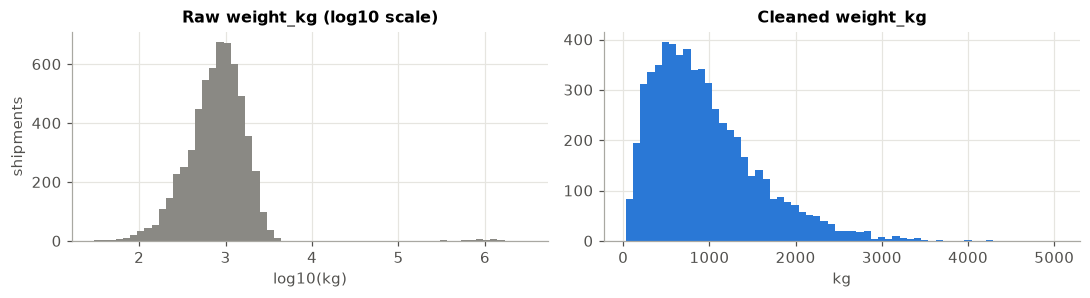

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
axes[0].hist(np.log10(raw["weight_kg"]), bins=60, color=NEUTRAL)
axes[0].set(title="Raw weight_kg (log10 scale)", xlabel="log10(kg)", ylabel="shipments")
axes[1].hist(df["weight_kg"], bins=60, color=ON_TIME)
axes[1].set(title="Cleaned weight_kg", xlabel="kg")
plt.tight_layout(); plt.show()

**Finding.** After cleaning, 6,000 unique shipments remain, with three service levels and no impossible weights. The late rate is unchanged at 20.6%. The isolated cluster on the right of the raw histogram (the gram-scale weights) is gone.

## 5. Exploratory data analysis
### 5.1 Class balance

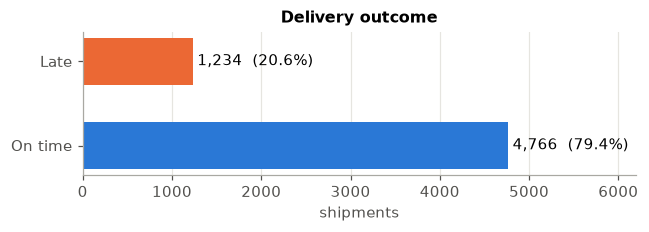

Always predicting 'on time' would score 79.4% accuracy and catch 0 late shipments.


In [51]:
counts = df["delivered_late"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.2))
bars = ax.barh(["On time", "Late"], counts.values, color=[ON_TIME, LATE], height=0.55)
for b, v in zip(bars, counts.values):
    ax.text(v + 50, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / counts.sum():.1%})", va="center")
ax.set(title="Delivery outcome", xlabel="shipments", xlim=(0, counts.max() * 1.3))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Always predicting 'on time' would score {1 - df['delivered_late'].mean():.1%} accuracy and catch 0 late shipments.")

### 5.2 Late rate by category

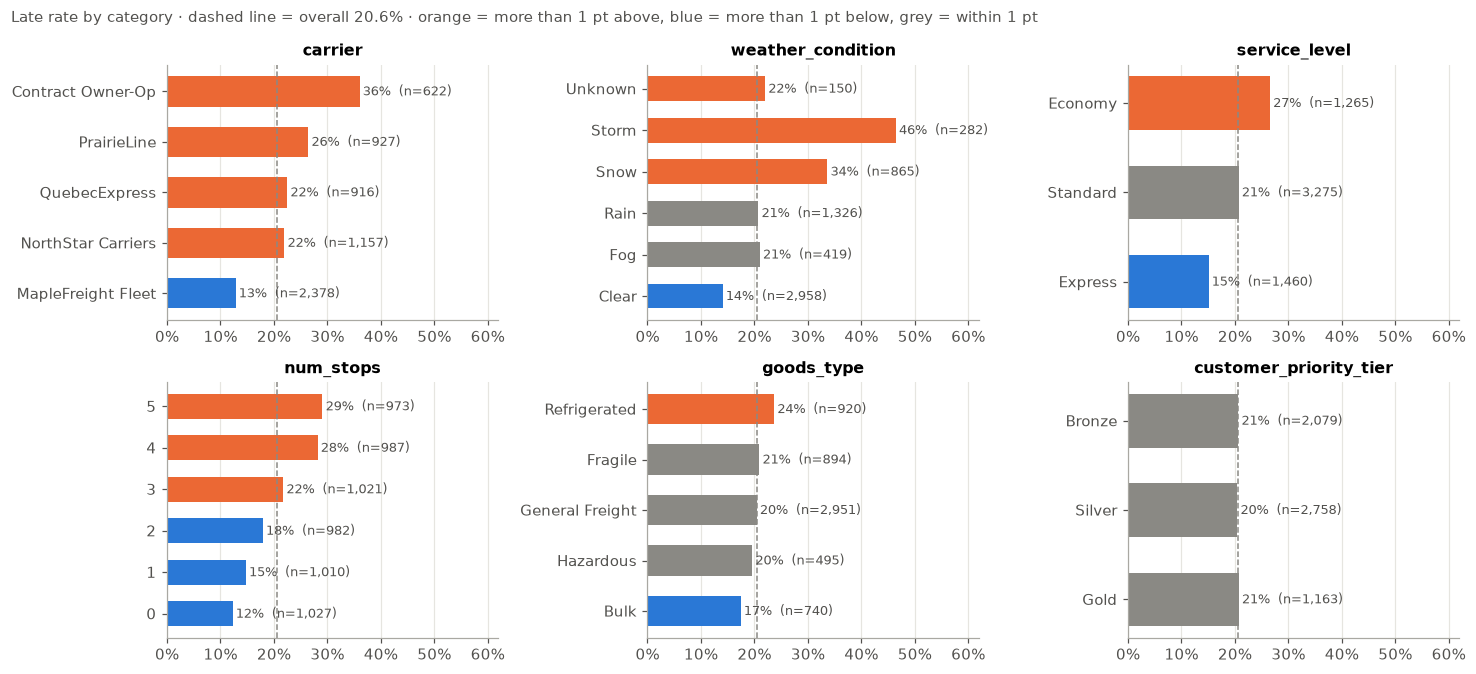

In [52]:
overall = df["delivered_late"].mean()

def late_rate(col):
    return df.groupby(col)["delivered_late"].agg(late_rate="mean", shipments="size")

panels = {
    "carrier": None,
    "weather_condition": ["Clear", "Fog", "Rain", "Snow", "Storm", "Unknown"],
    "service_level": ["Express", "Standard", "Economy"],
    "num_stops": [0, 1, 2, 3, 4, 5],
    "goods_type": None,
    "customer_priority_tier": ["Gold", "Silver", "Bronze"],
}
fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.2))
for ax, (col, order) in zip(axes.ravel(), panels.items()):
    t = late_rate(col)
    t = t.loc[order] if order is not None else t.sort_values("late_rate")
    colours = [LATE if r > overall + 0.01 else ON_TIME if r < overall - 0.01 else NEUTRAL for r in t["late_rate"]]
    ax.barh(t.index.astype(str), t["late_rate"], color=colours, height=0.6)
    ax.axvline(overall, color=NEUTRAL, ls="--", lw=1)
    for i, (r, n) in enumerate(zip(t["late_rate"], t["shipments"])):
        ax.text(r + 0.006, i, f"{r:.0%}  (n={n:,})", va="center", fontsize=8.5, color=INK)
    ax.set(title=col, xlim=(0, 0.62)); ax.xaxis.set_major_formatter(pct)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Late rate by category · dashed line = overall {overall:.1%} · "
             "orange = more than 1 pt above, blue = more than 1 pt below, grey = within 1 pt",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

In [53]:
# Which categorical columns are actually associated with lateness? (chi-square test of independence)
rows = []
for col in cat_cols + ["num_stops", "is_cross_border", "shipment_month"]:
    ct = pd.crosstab(df[col], df["delivered_late"])
    chi2, p, _, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    r = df.groupby(col)["delivered_late"].mean()
    rows.append({"feature": col, "levels": ct.shape[0], "lowest late rate": f"{r.min():.1%}",
                 "highest late rate": f"{r.max():.1%}", "Cramér's V": round(cramers_v, 3),
                 "p-value": f"{p:.1e}", "significant (p<0.01)": "yes" if p < 0.01 else "no"})
association = pd.DataFrame(rows).sort_values("Cramér's V", ascending=False).reset_index(drop=True)
association

,feature,levels,lowest late rate,highest late rate,Cramér's V,p-value,significant (p<0.01)
0,weather_condition,6,14.1%,46.5%,0.217,4.4e-59,yes
1,carrier,5,12.8%,36.0%,0.183,2.3e-42,yes
2,num_stops,6,12.3%,29.1%,0.157,4.9e-30,yes
3,service_level,3,15.1%,26.6%,0.096,1.2e-12,yes
4,shipment_month,12,17.7%,24.9%,0.059,3.7e-02,no
5,goods_type,5,17.4%,23.7%,0.042,3.5e-02,no
6,is_cross_border,2,20.1%,24.4%,0.034,9.5e-03,yes
7,destination_city,10,19.0%,23.3%,0.034,6.6e-01,no
8,origin_city,7,19.0%,21.6%,0.021,8.5e-01,no
9,customer_priority_tier,3,20.4%,20.7%,0.003,9.8e-01,no


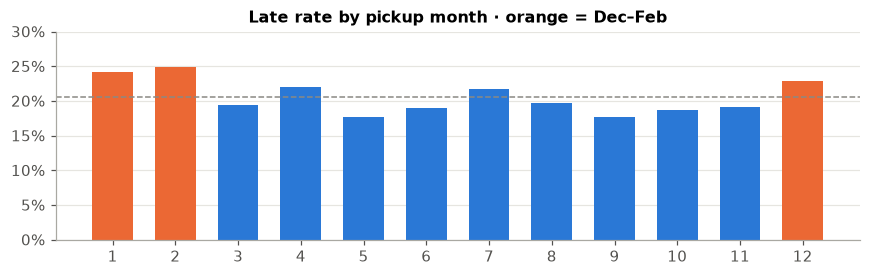

Dec–Feb late rate 24.0% vs rest of year 19.4%


In [54]:
months = late_rate("shipment_month")
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(months.index, months["late_rate"], color=[LATE if m in (12, 1, 2) else ON_TIME for m in months.index], width=0.65)
ax.axhline(overall, color=NEUTRAL, ls="--", lw=1)
ax.set(title="Late rate by pickup month · orange = Dec–Feb", xticks=range(1, 13), ylim=(0, 0.3))
ax.yaxis.set_major_formatter(pct); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
winter = df["shipment_month"].isin([12, 1, 2])
print(f"Dec–Feb late rate {df.loc[winter, 'delivered_late'].mean():.1%} vs rest of year {df.loc[~winter, 'delivered_late'].mean():.1%}")

### 5.3 Numeric features by outcome

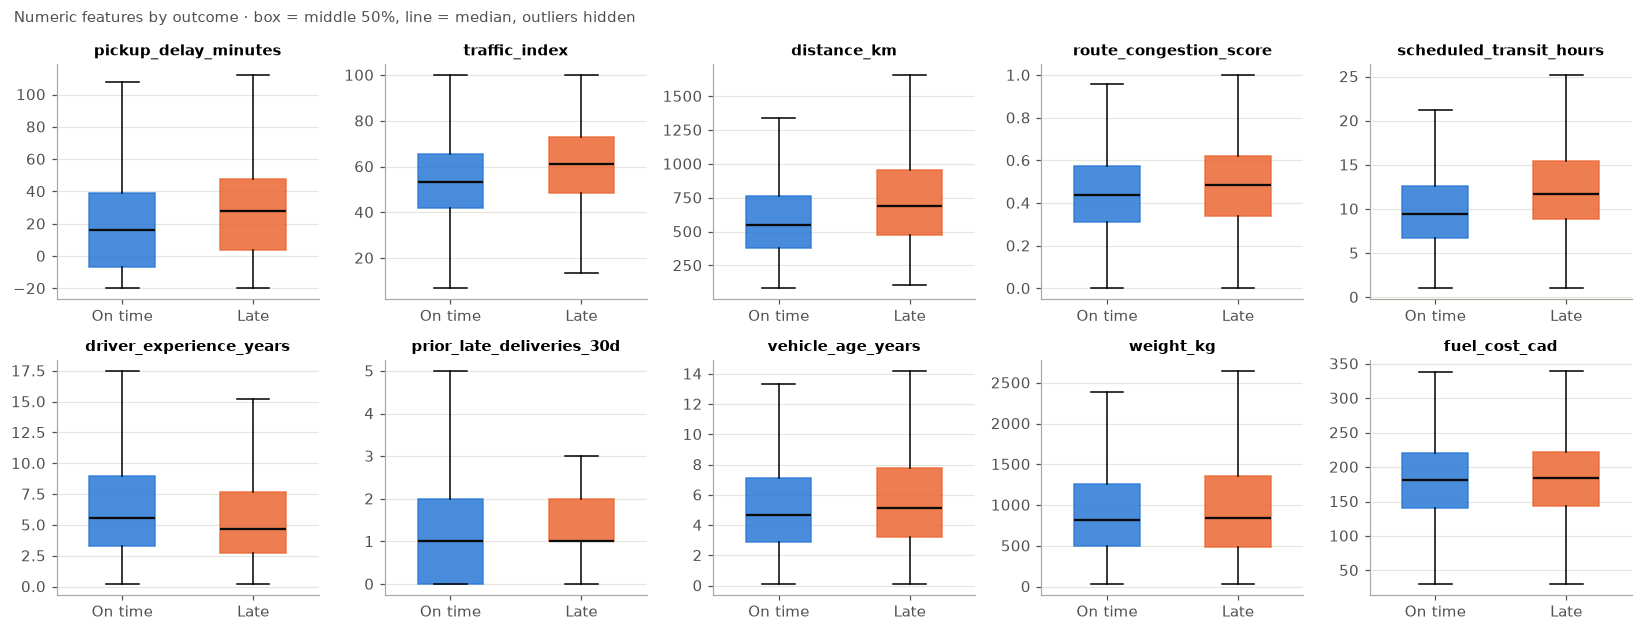

In [55]:
num_cols = ["pickup_delay_minutes", "traffic_index", "distance_km", "route_congestion_score",
            "scheduled_transit_hours", "driver_experience_years", "prior_late_deliveries_30d",
            "vehicle_age_years", "weight_kg", "fuel_cost_cad"]
fig, axes = plt.subplots(2, 5, figsize=(15, 5.8))
for ax, col in zip(axes.ravel(), num_cols):
    groups = [df.loc[df["delivered_late"] == k, col].dropna() for k in (0, 1)]
    bp = ax.boxplot(groups, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color="#0b0b0b", lw=1.5))
    for patch, c in zip(bp["boxes"], [ON_TIME, LATE]):
        patch.set(facecolor=c, edgecolor=c, alpha=0.85)
    ax.set_xticks([1, 2], ["On time", "Late"])
    ax.set_title(col, fontsize=9.5); ax.grid(axis="x", visible=False)
fig.suptitle("Numeric features by outcome · box = middle 50%, line = median, outliers hidden",
             x=0.01, ha="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

In [56]:
# How well does each number separate late from on-time on its own? (0.5 = no signal, 1.0 = perfect)
rows = []
for col in num_cols + ["num_stops"]:
    s = df[[col, "delivered_late"]].dropna()
    auc = roc_auc_score(s["delivered_late"], s[col])
    rows.append({"feature": col,
                 "median on time": s.loc[s["delivered_late"] == 0, col].median(),
                 "median late": s.loc[s["delivered_late"] == 1, col].median(),
                 "single-feature AUC": round(max(auc, 1 - auc), 3),
                 "direction": "higher → more late" if auc >= 0.5 else "lower → more late"})
numeric_signal = pd.DataFrame(rows).sort_values("single-feature AUC", ascending=False).reset_index(drop=True)
numeric_signal

,feature,median on time,median late,single-feature AUC,direction
0,scheduled_transit_hours,9.4000,11.7200,0.642,higher → more late
1,distance_km,548.0000,688.8500,0.621,higher → more late
2,traffic_index,53.4000,61.3000,0.614,higher → more late
3,num_stops,2.0000,3.0000,0.609,higher → more late
4,pickup_delay_minutes,16.0000,28.0000,0.593,higher → more late
5,prior_late_deliveries_30d,1.0000,1.0000,0.575,higher → more late
6,route_congestion_score,0.4365,0.4865,0.566,higher → more late
7,driver_experience_years,5.6000,4.7000,0.564,lower → more late
8,vehicle_age_years,4.7000,5.1000,0.539,higher → more late
9,weight_kg,818.1000,841.2500,0.515,higher → more late


### 5.4 Correlations and interactions

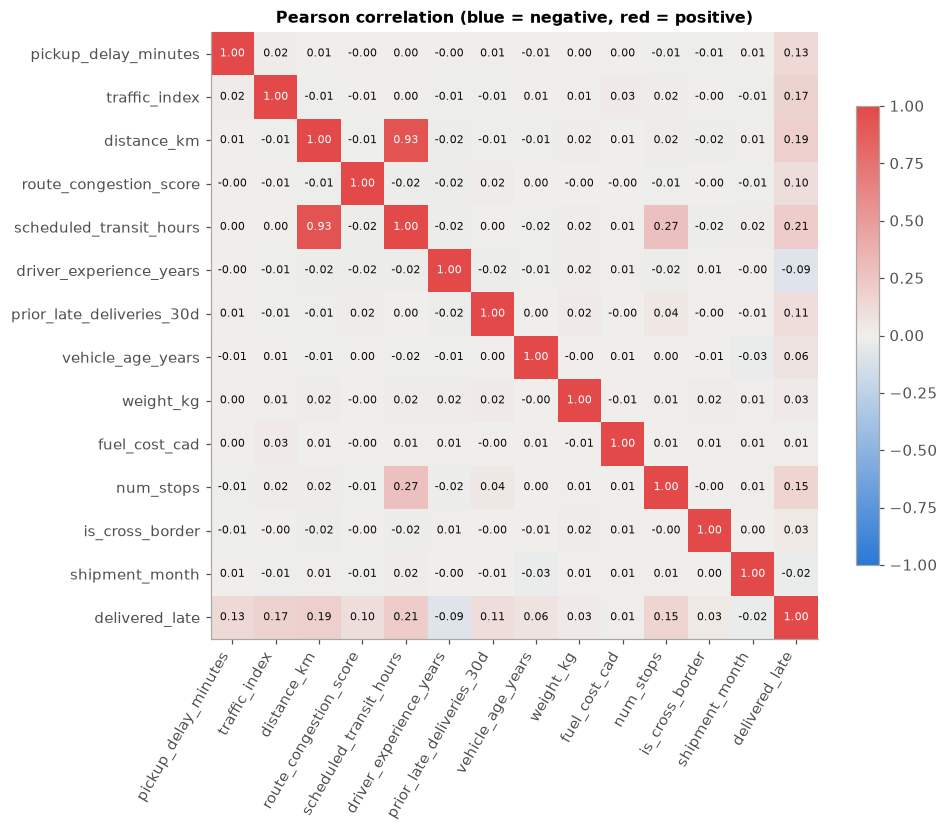

In [57]:
corr_cols = num_cols + ["num_stops", "is_cross_border", "shipment_month", "delivered_late"]
corr = df[corr_cols].corr()
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False); ax.set_title("Pearson correlation (blue = negative, red = positive)")
fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout(); plt.show()

In [58]:
# Late rate for carrier × weather (cells are % late; shipment counts below)
pivot = df.pivot_table(index="carrier", columns="weather_condition", values="delivered_late", aggfunc="mean")
pivot = pivot[["Clear", "Fog", "Rain", "Snow", "Storm", "Unknown"]]
display((pivot * 100).round(0).astype(int).astype(str) + "%")
display(pd.crosstab(df["carrier"], df["weather_condition"])[pivot.columns])

weather_condition,Clear,Fog,Rain,Snow,Storm,Unknown
carrier,,,,,,
Contract Owner-Op,29%,34%,36%,55%,56%,42%
MapleFreight Fleet,7%,15%,13%,22%,38%,12%
NorthStar Carriers,16%,23%,22%,35%,45%,21%
PrairieLine,17%,32%,26%,41%,56%,39%
QuebecExpress,16%,19%,23%,40%,59%,16%


weather_condition,Clear,Fog,Rain,Snow,Storm,Unknown
carrier,,,,,,
Contract Owner-Op,308,32,153,92,25,12
MapleFreight Fleet,1172,179,507,347,117,56
NorthStar Carriers,556,90,258,168,56,29
PrairieLine,450,60,198,139,52,28
QuebecExpress,472,58,210,119,32,25


**Findings: EDA**
- **Weather and carrier are the two strongest categorical drivers** (the highest Cramér's V).
  - Storms (46% late) and snow (34%) are far worse than clear days (14%).
  - Contract owner-operators are late 36% of the time, almost three times the company's own fleet (13%). PrairieLine (26%), QuebecExpress and NorthStar (22%) sit in between.
  - The two effects stack. In the carrier × weather table, owner-operators are late 55–56% of the time in snow or storm, while the own fleet on a clear day is late only 7%.
- **Route complexity adds up.** The late rate climbs steadily from 12% with no stops to 29% with five. Longer distances, heavier traffic and historically congested routes all push it up too.
- **A late pickup carries through.** Late shipments left a median of 28 min late versus 16 min for on-time ones. Pickup delay is also the earliest warning sign dispatch can actually see.
- **Service level.** Economy is late 27% of the time against 15% for Express.
- **Smaller effects.** Inexperienced drivers, older vehicles, cross-border trips (24% vs 20%), refrigerated goods (24%) and Dec–Feb pickups (24% vs 19%) each add a little. Goods type and month are only borderline significant on their own (p ≈ 0.04).
- **No signal:**
  - customer tier (20.4–20.7% across tiers), origin city and destination city, with chi-square p-values of 0.66–0.98
  - weight and fuel cost, with single-feature AUCs of 0.51–0.52
- **Correlated pair.** `distance_km` and `scheduled_transit_hours` correlate at r = 0.93, because the promise is built from the distance. Logistic regression's L2 penalty copes with this, but these two coefficients have to be read together. With distance held fixed, a *longer* promise means *more* slack.

## 6. Feature engineering
Each candidate below encodes a specific operational hypothesis. Section 8.3 keeps only the ones that improve cross-validated performance.

| Feature | Hypothesis |
|---|---|
| `pickup_delay_share` | A 60-minute pickup delay matters more on a 4-hour promise than on a 20-hour one |
| `required_speed_kmh` | A promise that needs a high average speed is tight |
| `stops_per_100km` | Many stops on a short route leave little slack |
| `is_winter` | Dec–Feb roads are slower than the single-day forecast suggests |
| `severe_weather` | Snow and storm behave alike, so group them |
| `same_city_route` | Local routes behave differently from intercity ones |

In [59]:
def add_features(d):
    d = d.copy()
    d["pickup_delay_share"] = d["pickup_delay_minutes"].clip(lower=0) / 60 / d["scheduled_transit_hours"]
    d["required_speed_kmh"] = d["distance_km"] / d["scheduled_transit_hours"]
    d["stops_per_100km"] = d["num_stops"] / d["distance_km"] * 100
    d["is_winter"] = d["shipment_month"].isin([12, 1, 2]).astype(int)
    d["severe_weather"] = d["weather_condition"].isin(["Snow", "Storm"]).astype(int)
    d["same_city_route"] = (d["origin_city"] == d["destination_city"]).astype(int)
    return d


ENGINEERED = ["pickup_delay_share", "required_speed_kmh", "stops_per_100km",
              "is_winter", "severe_weather", "same_city_route"]
df = add_features(df)
display(df.groupby("delivered_late")[ENGINEERED].mean().T.rename(columns={0: "mean on time", 1: "mean late"}).round(3))

delivered_late,mean on time,mean late
pickup_delay_share,0.050,0.051
required_speed_kmh,61.442,59.690
stops_per_100km,0.504,0.527
is_winter,0.241,0.293
severe_weather,0.152,0.342
same_city_route,0.077,0.079


## 7. Data preparation
- **Split:** 80% training, 20% test, stratified so both keep the 20.6% late rate. The test set is used once, at the end. All model choices (feature set, model type, hyper-parameters, alert threshold) come from 5-fold cross-validation on the training set.
- **Pipeline:** median imputation for numbers (fitted per fold), standard scaling (needed for logistic regression's penalty), and one-hot encoding for categories, with unseen categories ignored at prediction time.
- **Excluded columns:** `shipment_id` (an identifier) and `actual_transit_hours` (leakage, already dropped).

In [60]:
BASE_NUM = ["shipment_month", "distance_km", "weight_kg", "num_stops", "is_cross_border",
            "scheduled_transit_hours", "pickup_delay_minutes", "driver_experience_years",
            "vehicle_age_years", "traffic_index", "route_congestion_score",
            "prior_late_deliveries_30d", "fuel_cost_cad"]
BASE_CAT = cat_cols

X = df[BASE_CAT + BASE_NUM + ENGINEERED]
y = df["delivered_late"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} shipments ({y_train.mean():.1%} late)")
print(f"Test:  {len(X_test):,} shipments ({y_test.mean():.1%} late)")


def make_preprocessor(num_features, cat_features, scale=True):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "accuracy": accuracy_score(y_true, pred)}


def oof_proba(model, cols, cv_=cv):
    """Out-of-fold probabilities on the training set: every row is scored by a model that never saw it."""
    return cross_val_predict(model, X_train[cols], y_train, cv=cv_, method="predict_proba")[:, 1]

Train: 4,800 shipments (20.6% late)
Test:  1,200 shipments (20.6% late)


## 8. Data modelling
### 8.1 Baselines
Two reference points:
1. **Majority class:** always predict "on time". This is the 79% accuracy the brief warns about.
2. **Baseline model:** plain logistic regression on the raw, cleaned features, with no imbalance handling and the default 0.5 threshold. Every other model is compared against this one.

In [61]:
RAW_FEATURES = BASE_CAT + BASE_NUM
majority = DummyClassifier(strategy="most_frequent")
baseline = Pipeline([("prep", make_preprocessor(BASE_NUM, BASE_CAT)),
                     ("model", LogisticRegression(max_iter=3000))])

cv_results = {}
cv_results["Majority class"] = metrics(y_train, oof_proba(majority, RAW_FEATURES))
cv_results["Baseline: logistic regression"] = metrics(y_train, oof_proba(baseline, RAW_FEATURES))
pd.DataFrame(cv_results).T.round(3)

,ROC-AUC,PR-AUC,precision,recall,F1,accuracy
Majority class,0.500,0.206,0.00,0.000,0.000,0.794
Baseline: logistic regression,0.811,0.560,0.63,0.329,0.432,0.822


The baseline ranks shipments well (ROC-AUC about 0.81), but at the default threshold it catches only a third of the late shipments. On imbalanced data a plain model's probabilities rarely cross 0.5 for the minority class. The imbalance has to be handled.

### 8.2 Handling the imbalance and comparing model families
Imbalance is handled with **class weights**: errors on late shipments count about 3.9 times as much as errors on on-time ones (`class_weight="balanced"`). This has the same effect as oversampling without inventing synthetic shipments. The decision threshold is tuned separately in Section 9.

Three model families are compared with the same 5 folds:
- weighted logistic regression
- random forest (balanced subsamples)
- histogram gradient boosting (balanced)

In [62]:
candidates = {
    "Logistic regression (balanced)": Pipeline([
        ("prep", make_preprocessor(BASE_NUM, BASE_CAT)),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "Random forest (balanced)": Pipeline([
        ("prep", make_preprocessor(BASE_NUM, BASE_CAT, scale=False)),
        ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient boosting (balanced)": Pipeline([
        ("prep", make_preprocessor(BASE_NUM, BASE_CAT, scale=False)),
        ("model", HistGradientBoostingClassifier(learning_rate=0.03, max_iter=400, max_leaf_nodes=7,
                                                 min_samples_leaf=40, l2_regularization=1.0,
                                                 class_weight="balanced", random_state=RANDOM_STATE))]),
}
for name, model in candidates.items():
    cv_results[name] = metrics(y_train, oof_proba(model, RAW_FEATURES))

comparison = pd.DataFrame(cv_results).T.round(3)
comparison

,ROC-AUC,PR-AUC,precision,recall,F1,accuracy
Majority class,0.500,0.206,0.000,0.000,0.000,0.794
Baseline: logistic regression,0.811,0.560,0.630,0.329,0.432,0.822
Logistic regression (balanced),0.810,0.559,0.419,0.727,0.532,0.736
Random forest (balanced),0.792,0.520,0.567,0.369,0.447,0.812
Gradient boosting (balanced),0.798,0.531,0.431,0.679,0.528,0.750


**Finding.** At the same 0.5 threshold, class weighting more than doubles recall over the baseline (0.33 → 0.73), and F1 rises from 0.43 to 0.53. Ranking quality (ROC-AUC, PR-AUC) barely moves. That is expected: weighting mostly shifts where the probabilities sit rather than how the model orders shipments.

The two tree ensembles do *not* beat logistic regression on PR-AUC, the threshold-free measure that matters most for a rare class. The drivers found in the EDA act roughly additively (more stops → later, worse weather → later), and that is exactly what a linear model on the log-odds captures. Logistic regression is also simple to explain to dispatch, so it is carried forward.

### 8.3 Feature selection by cross-validation
Each change is tested against the weighted logistic regression on raw features. Every configuration is scored with 3 different 5-fold shuffles, so small differences can be told apart from fold-to-fold noise.

In [63]:
def lr_balanced(num_features, cat_features, C=1.0):
    return Pipeline([("prep", make_preprocessor(num_features, cat_features)),
                     ("model", LogisticRegression(max_iter=3000, class_weight="balanced", C=C))])


def repeated_pr_auc(num_features, cat_features, C=1.0):
    scores = []
    for seed in (0, 1, 2):
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        p = oof_proba(lr_balanced(num_features, cat_features, C), cat_features + num_features, folds)
        scores.append((roc_auc_score(y_train, p), average_precision_score(y_train, p)))
    return np.mean(scores, axis=0), np.std(scores, axis=0)


NO_CITY_CAT = [c for c in BASE_CAT if c not in ("origin_city", "destination_city")]
configs = {"Raw features (all)": (BASE_NUM, BASE_CAT),
           "Drop origin & destination city": (BASE_NUM, NO_CITY_CAT)}
for f in ENGINEERED:
    configs[f"No cities + {f}"] = (BASE_NUM + [f], NO_CITY_CAT)
configs["No cities + all engineered"] = (BASE_NUM + ENGINEERED, NO_CITY_CAT)

rows = []
for name, (nums, cats) in configs.items():
    (roc, pr), (_, pr_sd) = repeated_pr_auc(nums, cats)
    rows.append({"configuration": name, "ROC-AUC": roc, "PR-AUC": pr, "PR-AUC sd": pr_sd})
ablation = pd.DataFrame(rows)
ablation["PR-AUC vs raw"] = ablation["PR-AUC"] - ablation.loc[0, "PR-AUC"]
ablation.round(4)

,configuration,ROC-AUC,PR-AUC,PR-AUC sd,PR-AUC vs raw
0,Raw features (all),0.8125,0.5597,0.0011,0.0000
1,Drop origin & destination city,0.8160,0.5635,0.0006,0.0039
2,No cities + pickup_delay_share,0.8153,0.5636,0.0006,0.0039
3,No cities + required_speed_kmh,0.8157,0.5632,0.0005,0.0035
4,No cities + stops_per_100km,0.8154,0.5627,0.0005,0.0030
5,No cities + is_winter,0.8167,0.5643,0.0007,0.0046
6,No cities + severe_weather,0.8160,0.5634,0.0007,0.0037
7,No cities + same_city_route,0.8161,0.5627,0.0008,0.0031
8,No cities + all engineered,0.8155,0.5623,0.0008,0.0026


**Finding.**
- Dropping the two city columns helps by more than the noise. They add 15 one-hot columns that carry no signal, which matches the chi-square tests in Section 5.
- Of the engineered features, only `is_winter` nudges the score up: +0.0007 PR-AUC on top of dropping the cities, about one standard deviation. It is kept because it is cheap and has a clear operational meaning.
- The other engineered features repeat information the model already has. Weather is already one-hot encoded, and pickup delay, distance and stops are already linear terms.
- Adding all six engineered features together is slightly worse than adding none.

The final feature set is the cleaned raw features **without the city columns, plus `is_winter`**. The gain is modest. Most of the predictive power comes from cleaning the data correctly and handling the imbalance, not from clever features.

### 8.4 Tuning the final model

In [64]:
FINAL_NUM = BASE_NUM + ["is_winter"]
FINAL_CAT = NO_CITY_CAT
FINAL_FEATURES = FINAL_CAT + FINAL_NUM

search = GridSearchCV(lr_balanced(FINAL_NUM, FINAL_CAT),
                      param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]},
                      scoring="average_precision", cv=cv)
search.fit(X_train[FINAL_FEATURES], y_train)
display(pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
        .rename(columns={"param_model__C": "C", "mean_test_score": "PR-AUC", "std_test_score": "sd"}).round(4))
BEST_C = search.best_params_["model__C"]
print(f"Best regularisation strength C = {BEST_C}")

final_model = lr_balanced(FINAL_NUM, FINAL_CAT, C=BEST_C)
final_oof = oof_proba(final_model, FINAL_FEATURES)
cv_results["Final: tuned logistic regression (balanced)"] = metrics(y_train, final_oof)
pd.DataFrame(cv_results).T.round(3)

,C,PR-AUC,sd
0,0.01,0.5530,0.0217
1,0.03,0.5637,0.0200
2,0.10,0.5671,0.0173
3,0.30,0.5683,0.0163
4,1.00,0.5683,0.0166
5,3.00,0.5683,0.0164


Best regularisation strength C = 1.0


,ROC-AUC,PR-AUC,precision,recall,F1,accuracy
Majority class,0.500,0.206,0.000,0.000,0.000,0.794
Baseline: logistic regression,0.811,0.560,0.630,0.329,0.432,0.822
Logistic regression (balanced),0.810,0.559,0.419,0.727,0.532,0.736
Random forest (balanced),0.792,0.520,0.567,0.369,0.447,0.812
Gradient boosting (balanced),0.798,0.531,0.431,0.679,0.528,0.750
Final: tuned logistic regression (balanced),0.815,0.565,0.423,0.740,0.538,0.739


**Finding.** PR-AUC is flat for C between 0.3 and 3, and the differences are far smaller than the fold-to-fold spread. Regularisation strength barely matters here, so C = 1 (the default) is kept. The final model has the best cross-validated ROC-AUC and PR-AUC of every model tried.

## 9. Model evaluation and alert threshold
### 9.1 Choosing the alert threshold
The threshold decides how many shipments get flagged, and that is an operational trade-off:
- **Too low:** dispatch is flooded with false alarms and starts ignoring the channel.
- **Too high:** most late shipments slip through and the credits get paid anyway.

The table translates each candidate threshold into weekly terms, at 8,000 shipments a week. It uses out-of-fold predictions on the training set, so the test set stays untouched.

In [65]:
def threshold_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        pred = proba >= t
        rows.append({"threshold": round(t, 2),
                     "precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred),
                     "F1": f1_score(y_true, pred), "flagged %": pred.mean(),
                     "alerts / week": pred.mean() * SHIPMENTS_PER_WEEK,
                     "late caught / week": (pred & (y_true == 1)).mean() * SHIPMENTS_PER_WEEK,
                     "late missed / week": (~pred & (y_true == 1)).mean() * SHIPMENTS_PER_WEEK})
    return pd.DataFrame(rows)


prec, rec, thr = precision_recall_curve(y_train, final_oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1])
THRESHOLD = round(float(thr[np.nanargmax(f1s)]), 2)
print(f"F1-maximising threshold on out-of-fold predictions: {THRESHOLD}")

sweep = threshold_table(y_train, final_oof, sorted(set(np.round(np.arange(0.30, 0.86, 0.05), 2)) | {THRESHOLD}))
display(sweep.round({"precision": 3, "recall": 3, "F1": 3, "flagged %": 3,
                     "alerts / week": 0, "late caught / week": 0, "late missed / week": 0}))

F1-maximising threshold on out-of-fold predictions: 0.6


,threshold,precision,recall,F1,flagged %,alerts / week,late caught / week,late missed / week
0,0.30,0.319,0.896,0.471,0.576,4612.0,1473.0,172.0
1,0.35,0.344,0.865,0.492,0.518,4142.0,1423.0,222.0
2,0.40,0.366,0.823,0.507,0.462,3693.0,1353.0,292.0
3,0.45,0.397,0.787,0.527,0.408,3265.0,1295.0,350.0
4,0.50,0.423,0.740,0.538,0.360,2877.0,1217.0,428.0
5,0.55,0.450,0.679,0.541,0.310,2483.0,1117.0,528.0
6,0.60,0.487,0.623,0.547,0.263,2105.0,1025.0,620.0
7,0.65,0.522,0.561,0.541,0.221,1770.0,923.0,722.0
8,0.70,0.560,0.477,0.515,0.175,1402.0,785.0,860.0
9,0.75,0.592,0.396,0.475,0.138,1100.0,652.0,993.0


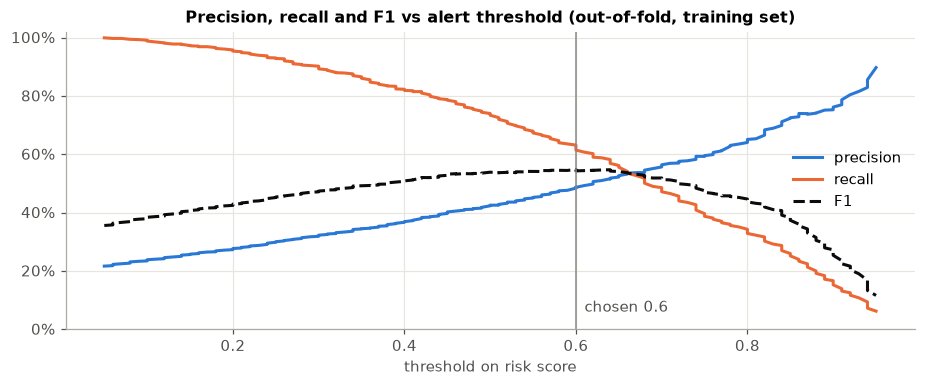

In [66]:
ts = np.linspace(0.05, 0.95, 181)
curve = threshold_table(y_train, final_oof, ts)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curve["threshold"], curve["precision"], color=ON_TIME, lw=2, label="precision")
ax.plot(curve["threshold"], curve["recall"], color=LATE, lw=2, label="recall")
ax.plot(curve["threshold"], curve["F1"], color="#0b0b0b", lw=2, ls="--", label="F1")
ax.axvline(THRESHOLD, color=NEUTRAL, lw=1)
ax.text(THRESHOLD + 0.01, 0.06, f"chosen {THRESHOLD}", color=INK)
ax.set(title="Precision, recall and F1 vs alert threshold (out-of-fold, training set)",
       xlabel="threshold on risk score", ylim=(0, 1.02))
ax.yaxis.set_major_formatter(pct); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

**Chosen alert threshold: 0.60** (the F1-maximising value on out-of-fold predictions). At 8,000 shipments a week this means:

- **About 2,100 alerts a week**, roughly 26% of shipments. Close to half of them (precision 0.49) are genuinely late, so a dispatcher's check pays off about one time in two.
- **About 62% of late shipments caught** (around 1,025 a week) while there is still time to act, against 33% for the baseline model.

Why not the other options:
- **Lower (0.40–0.45).** Recall rises to 79–82%, but 41–46% of *all* shipments get flagged and fewer than 4 alerts in 10 are real. Dispatch would spend most of its time on false alarms, and alert fatigue would empty the channel of meaning.
- **Higher (0.70+).** Precision reaches 0.56 or more, but fewer than half of the late shipments are caught, which leaves most of the service credits on the table.
- **The F1 curve is flat between about 0.50 and 0.65.** 0.60 sits in the middle of that plateau, so small shifts in the data won't move it to a much worse operating point.

The brief gives no dollar figures, so F1 is the neutral choice: it treats a miss and a false alarm as equally bad. If finance later puts a cost on each, the same table shows where to move. A missed late delivery (credit plus re-delivery) is probably dearer than a dispatcher's phone call, which would argue for a lower threshold, but only if dispatch has the capacity to work the extra alerts. The Slack message lists shipments by risk, so dispatch always sees the most urgent ones first.

### 9.2 Test-set results: baseline vs final model

In [67]:
baseline.fit(X_train[RAW_FEATURES], y_train)
majority.fit(X_train[RAW_FEATURES], y_train)
final_model.fit(X_train[FINAL_FEATURES], y_train)

p_major = majority.predict_proba(X_test[RAW_FEATURES])[:, 1]
p_base = baseline.predict_proba(X_test[RAW_FEATURES])[:, 1]
p_final = final_model.predict_proba(X_test[FINAL_FEATURES])[:, 1]

test_results = pd.DataFrame({
    "Majority class": metrics(y_test, p_major),
    "Baseline LR (threshold 0.5)": metrics(y_test, p_base),
    "Final LR (threshold 0.5)": metrics(y_test, p_final),
    f"Final LR (threshold {THRESHOLD})": metrics(y_test, p_final, THRESHOLD),
}).T.round(3)
test_results

,ROC-AUC,PR-AUC,precision,recall,F1,accuracy
Majority class,0.500,0.206,0.000,0.000,0.000,0.794
Baseline LR (threshold 0.5),0.829,0.600,0.696,0.352,0.468,0.835
Final LR (threshold 0.5),0.836,0.614,0.442,0.745,0.555,0.754
Final LR (threshold 0.6),0.836,0.614,0.519,0.648,0.577,0.804


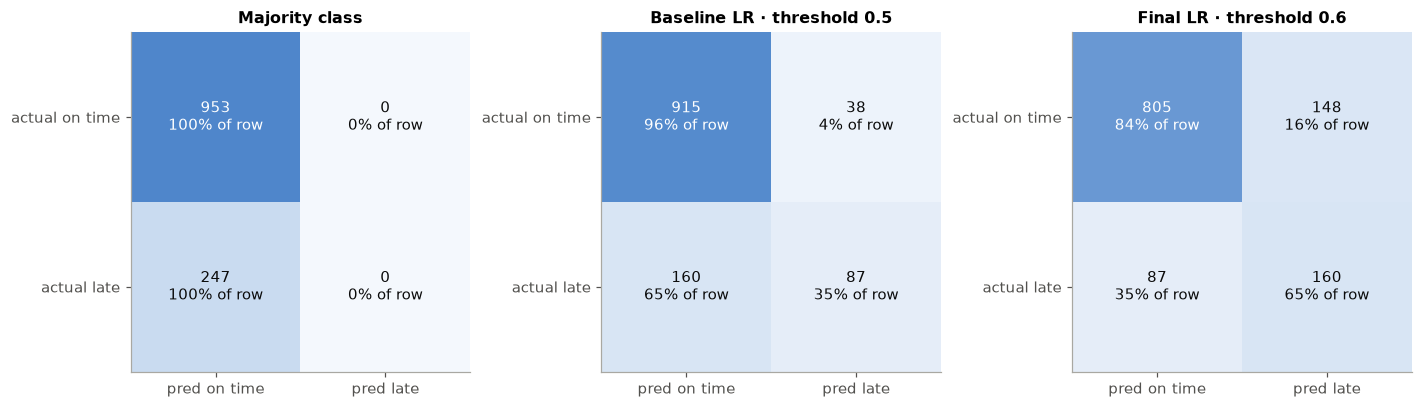

Final model at threshold 0.6 — classification report on the test set:
              precision    recall  f1-score   support

     on time      0.902     0.845     0.873       953
        late      0.519     0.648     0.577       247

    accuracy                          0.804      1200
   macro avg      0.711     0.746     0.725      1200
weighted avg      0.824     0.804     0.812      1200



In [68]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("Majority class", p_major, 0.5), ("Baseline LR · threshold 0.5", p_base, 0.5),
          (f"Final LR · threshold {THRESHOLD}", p_final, THRESHOLD)]
blues = LinearSegmentedColormap.from_list("b", ["#f4f8fd", "#256abf"])
for ax, (title, p, t) in zip(axes, panels):
    cm = confusion_matrix(y_test, (p >= t).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap=blues, vmin=0, vmax=len(y_test))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j] / cm[i].sum():.0%} of row", ha="center", va="center",
                    color="white" if cm[i, j] > len(y_test) * 0.45 else "#0b0b0b", fontsize=9.5)
    ax.set_xticks([0, 1], ["pred on time", "pred late"]); ax.set_yticks([0, 1], ["actual on time", "actual late"])
    ax.set_title(title); ax.grid(False)
plt.tight_layout(); plt.show()

print(f"Final model at threshold {THRESHOLD} — classification report on the test set:")
print(classification_report(y_test, (p_final >= THRESHOLD).astype(int), target_names=["on time", "late"], digits=3))

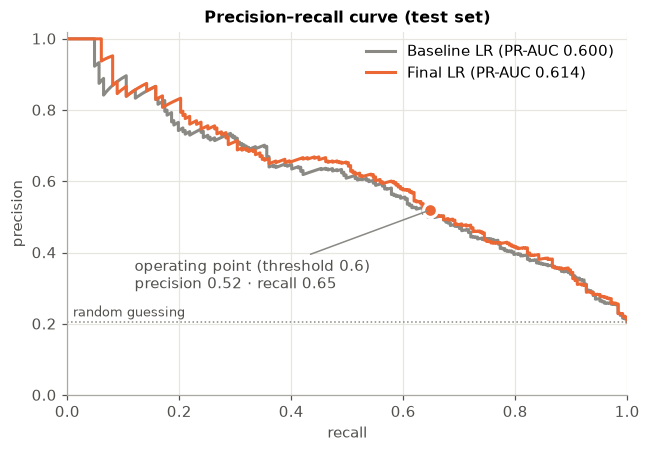

In [69]:
# Precision–recall curves on the test set
fig, ax = plt.subplots(figsize=(6, 4.2))
for name, p, c, ls in [("Baseline LR", p_base, NEUTRAL, "-"), ("Final LR", p_final, LATE, "-")]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=c, lw=2, ls=ls, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
op_p, op_r = precision_score(y_test, p_final >= THRESHOLD), recall_score(y_test, p_final >= THRESHOLD)
ax.plot(op_r, op_p, "o", ms=9, color=LATE, mec="white", mew=2)
ax.annotate(f"operating point (threshold {THRESHOLD})\nprecision {op_p:.2f} · recall {op_r:.2f}", (op_r, op_p),
            xytext=(0.12, 0.3), color=INK, arrowprops=dict(arrowstyle="-", color=NEUTRAL))
ax.axhline(y_test.mean(), color=NEUTRAL, ls=":", lw=1)
ax.text(0.01, y_test.mean() + 0.015, "random guessing", color=INK, fontsize=8.5)
ax.set(title="Precision–recall curve (test set)", xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [70]:
# How stable are the test numbers? 1,000 bootstrap resamples of the test set.
# Baseline and final model are scored on the SAME resample each time, so the F1 gain is a paired comparison.
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
pf, pb = (p_final >= THRESHOLD).astype(int), (p_base >= 0.5).astype(int)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    f_final, f_base = f1_score(yt[i], pf[i]), f1_score(yt[i], pb[i])
    boot.append((precision_score(yt[i], pf[i]), recall_score(yt[i], pf[i]), f_final, f_final - f_base))
boot = pd.DataFrame(boot, columns=["precision (final)", "recall (final)", "F1 (final)", "F1 gain vs baseline"])
print(f"F1 gain was positive in {(boot['F1 gain vs baseline'] > 0).mean():.1%} of resamples")
boot.quantile([0.025, 0.5, 0.975]).T.rename(columns={0.025: "2.5%", 0.5: "median", 0.975: "97.5%"}).round(3)

F1 gain was positive in 100.0% of resamples


,2.5%,median,97.5%
precision (final),0.463,0.520,0.574
recall (final),0.592,0.647,0.711
F1 (final),0.528,0.577,0.625
F1 gain vs baseline,0.050,0.110,0.162


**Findings: evaluation (test set, 1,200 shipments never used for any decision)**
| Model | Precision | Recall | F1 | Late caught (of 247) |
|---|---|---|---|---|
| Majority class | 0.00 | 0.00 | 0.00 | 0 |
| Baseline LR, threshold 0.5 | 0.70 | 0.35 | 0.47 | 87 |
| **Final LR, threshold 0.60** | **0.52** | **0.65** | **0.58** | **160** |

- The **majority-class** model is 79% accurate and catches nothing, which confirms that accuracy is the wrong yardstick here.
- The **baseline** is precise but timid: it misses 65% of late shipments.
- The **final model** catches 160 of the 247 late shipments, 73 more than the baseline. The cost is 110 extra false alarms (148 vs 38).
  - That is a good trade. Each false alarm costs a dispatcher a few minutes; each catch can save a service credit and a re-delivery.
  - F1 rises by 0.11, and the gain is positive in every bootstrap resample, so it is not test-set luck.
- **No sign of overfitting.** Test scores are in line with, and slightly above, the cross-validation estimates: F1 0.58 on test vs 0.55 in CV, PR-AUC 0.61 vs 0.565.
- **What the imbalance handling changed.** The baseline and final PR curves nearly overlap. Class weighting and threshold tuning changed *where* the model operates, not how well it ranks shipments.
- **Room to improve.** PR-AUC of 0.61 is about three times the random-guess level of 0.21, but well short of perfect. Section 13 covers what extra data could close the gap.

## 10. Model explainability
### 10.1 What the model learned: odds ratios
Logistic regression coefficients are changes in log-odds. Below they are converted into odds ratios per *practical* unit. An odds ratio of 1.5 means the odds of a late delivery are 50% higher; 0.7 means 30% lower.

In [71]:
prep = final_model.named_steps["prep"]
lr = final_model.named_steps["model"]
names = prep.get_feature_names_out()
coef = pd.Series(lr.coef_[0], index=names)
scaler = prep.named_transformers_["num"].named_steps["scale"]
sd = pd.Series(scaler.scale_, index=FINAL_NUM)

units = {"pickup_delay_minutes": (30, "+30 min pickup delay"), "traffic_index": (10, "+10 traffic index points"),
         "distance_km": (100, "+100 km distance"), "num_stops": (1, "+1 intermediate stop"),
         "route_congestion_score": (0.1, "+0.1 route congestion score"),
         "prior_late_deliveries_30d": (1, "+1 carrier late delivery in past 30 days"),
         "driver_experience_years": (5, "+5 years driver experience"), "vehicle_age_years": (5, "+5 years vehicle age"),
         "is_cross_border": (1, "cross-border (vs domestic)"), "is_winter": (1, "Dec–Feb pickup"),
         "scheduled_transit_hours": (1, "+1 h promised transit (same distance)")}
numeric_or = pd.DataFrame([{"change": label, "odds ratio": np.exp(coef[f"num__{f}"] / sd[f] * u)}
                           for f, (u, label) in units.items()]).sort_values("odds ratio", ascending=False)


def contrast(col, ref):
    rows = []
    for level in df[col].unique():
        if level != ref:
            rows.append({"change": f"{col}: {level} vs {ref}",
                         "odds ratio": np.exp(coef[f"cat__{col}_{level}"] - coef[f"cat__{col}_{ref}"])})
    return rows


cat_or = pd.DataFrame(contrast("carrier", "MapleFreight Fleet") + contrast("weather_condition", "Clear")
                      + contrast("service_level", "Express") + contrast("goods_type", "General Freight")
                      ).sort_values("odds ratio", ascending=False)
display(numeric_or.round(2).reset_index(drop=True))
display(cat_or.round(2).reset_index(drop=True))

,change,odds ratio
0,cross-border (vs domestic),1.74
1,+30 min pickup delay,1.50
2,+10 traffic index points,1.36
3,+1 intermediate stop,1.36
4,+1 carrier late delivery in past 30 days,1.33
5,Dec–Feb pickup,1.30
6,+5 years vehicle age,1.29
7,+100 km distance,1.22
8,+0.1 route congestion score,1.17
9,+1 h promised transit (same distance),0.98


,change,odds ratio
0,weather_condition: Storm vs Clear,10.65
1,carrier: Contract Owner-Op vs MapleFreight Fleet,5.27
2,weather_condition: Snow vs Clear,4.32
3,carrier: PrairieLine vs MapleFreight Fleet,3.07
4,service_level: Economy vs Express,2.64
5,carrier: NorthStar Carriers vs MapleFreight Fleet,2.33
6,carrier: QuebecExpress vs MapleFreight Fleet,2.23
7,weather_condition: Unknown vs Clear,1.84
8,weather_condition: Rain vs Clear,1.78
9,weather_condition: Fog vs Clear,1.71


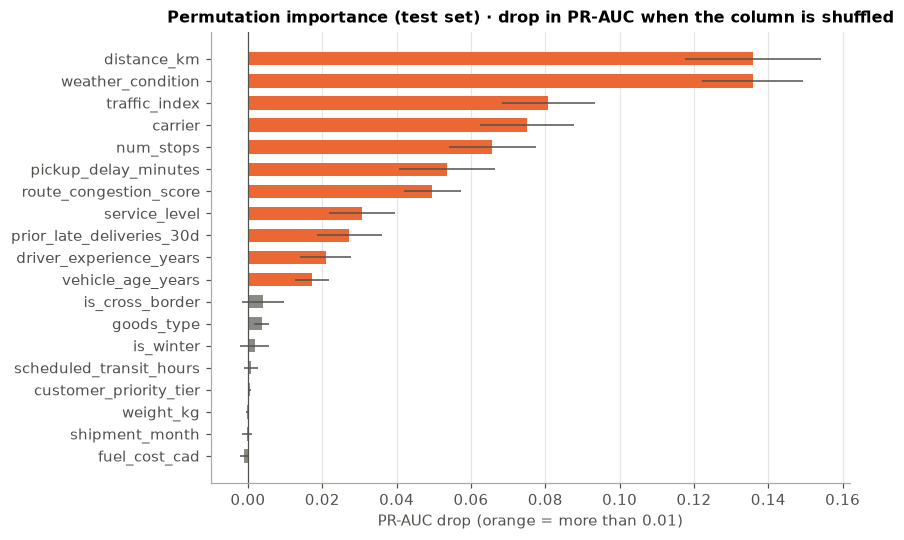

In [72]:
# Permutation importance on the test set: how much PR-AUC drops when one column is shuffled
perm = permutation_importance(final_model, X_test[FINAL_FEATURES], y_test, scoring="average_precision",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": FINAL_FEATURES, "drop": perm.importances_mean, "sd": perm.importances_std}
                   ).sort_values("drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp["feature"], imp["drop"], xerr=imp["sd"], color=[LATE if v > 0.01 else NEUTRAL for v in imp["drop"]],
        height=0.6, error_kw=dict(ecolor=INK, lw=1))
ax.axvline(0, color=INK, lw=0.8)
ax.set(title="Permutation importance (test set) · drop in PR-AUC when the column is shuffled",
       xlabel="PR-AUC drop (orange = more than 0.01)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Findings: explainability**
- **Biggest effects (odds ratios).**
  - A storm forecast multiplies the odds of a late delivery by about 10.7 compared with clear weather; snow by about 4.3.
  - An owner-operator multiplies them by about 5.3 compared with the own fleet.
  - Economy service raises them about 2.6× compared with Express.
  - Each extra 30 minutes of pickup delay adds about 50% to the odds, each extra stop about 36%, and each 10 traffic points about 36%. Five more years of driver experience *cuts* the odds by about 27%.
- **Permutation importance** ranks distance, weather, traffic, carrier, stops, pickup delay and route congestion as the columns the model leans on most, followed by service level, carrier late history, driver experience and vehicle age.
  - Distance tops the list partly because it is tied to `scheduled_transit_hours`. Shuffling distance breaks the distance-versus-promise pairing the model relies on, which inflates its importance.
- **Cross-border** has a large odds ratio (1.74) but low permutation importance, because only 11% of shipments cross the border. It matters a lot for the few shipments it applies to.
- **Weight, fuel cost, customer tier and month** contribute essentially nothing, which matches the EDA.
- **The model's logic is plausible to dispatch.** Storms, owner-operators, late pickups, heavy traffic and multi-stop routes all raise risk; experienced drivers and Express service lower it. No effect points the "wrong" way.

### 10.2 Explaining individual alerts
Dispatch needs to know *why* a shipment was flagged in order to act on it. For logistic regression, each feature's contribution to a shipment's log-odds is simply its coefficient times its scaled value. The two largest positive contributions become a short reason in the Slack message. Carrier is left out of the reason because it is already shown on the alert line.

In [73]:
FEATURE_OF = {}
for n in names:
    raw_name = n.split("__", 1)[1]
    FEATURE_OF[n] = next((c for c in FINAL_CAT if raw_name.startswith(c + "_")), raw_name)


def describe(feature, row):
    v = row[feature]
    if pd.isna(v):
        return f"{feature.replace('_', ' ')} unknown"
    text = {   # lambdas, so only the matching template is formatted
        "weather_condition": lambda: f"{str(v).lower()} forecast",
        "pickup_delay_minutes": lambda: f"picked up {v:.0f} min late",
        "traffic_index": lambda: f"traffic {v:.0f}/100",
        "distance_km": lambda: f"{v:,.0f} km route",
        "num_stops": lambda: f"{v:.0f} stops",
        "service_level": lambda: f"{v} service",
        "route_congestion_score": lambda: f"congested route ({v:.2f})",
        "prior_late_deliveries_30d": lambda: f"carrier {v:.0f} late in 30d",
        "driver_experience_years": lambda: f"driver {v:.1f} yrs exp.",
        "vehicle_age_years": lambda: f"vehicle {v:.0f} yrs old",
        "is_cross_border": lambda: "cross-border",
        "is_winter": lambda: "winter month",
        "goods_type": lambda: f"{str(v).lower()} goods",
    }
    return text.get(feature, lambda: f"{feature.replace('_', ' ')} {v}")()


def top_reasons(rows, k=2, exclude=("carrier",)):
    contrib = pd.DataFrame(prep.transform(rows[FINAL_FEATURES]) * lr.coef_[0], columns=names, index=rows.index)
    by_feature = contrib.T.groupby(FEATURE_OF).sum().T.drop(columns=list(exclude), errors="ignore")
    out = []
    for idx, r in by_feature.iterrows():
        top = r[r > 0].sort_values(ascending=False).head(k).index
        out.append(", ".join(describe(f, rows.loc[idx]) for f in top))
    return pd.Series(out, index=rows.index)


example = X_test.loc[[pd.Series(p_final, index=X_test.index).idxmax()]]
print("Highest-risk test shipment:", df.loc[example.index, "shipment_id"].item(), "→", top_reasons(example).item())

Highest-risk test shipment: SHP-100936 → 1,512 km route, storm forecast


## 11. Slack alert integration
### 11.1 One-time setup
1. Create a free Slack workspace (or use an existing one) and a channel called **#dispatch-alerts**.
2. Go to https://api.slack.com/apps → **Create New App** → *From scratch*, and pick the workspace.
3. Under **Incoming Webhooks**, switch it on, then **Add New Webhook to Workspace** → choose `#dispatch-alerts` → *Allow*.
4. Copy the webhook URL into a file named `.env` next to this notebook:
   ```
   SLACK_WEBHOOK_URL=<paste the URL here>
   ```
   `.env` is listed in `.gitignore`, so it never reaches GitHub. The repo only contains `.env.example`.

The webhook URL is a password: anyone who has it can post to the channel. The code below never prints it, and on errors it reports only the error *type*, because `requests` exception messages contain the full URL.

In [74]:
load_dotenv()                                     # reads .env from the working directory, if present
SLACK_WEBHOOK_URL = os.getenv("SLACK_WEBHOOK_URL")
print("Slack webhook configured:", bool(SLACK_WEBHOOK_URL))   # True/False only — never the URL itself

Slack webhook configured: True


### 11.2 Score the in-transit shipments
The 1,200 test shipments stand in for one day of in-transit freight: 8,000 a week is roughly 1,150 a day. The model has never seen them. In production this cell would read the live dispatch feed instead and run on a schedule, for example every hour and again right after each pickup is scanned.

In [75]:
in_transit = df.loc[X_test.index].copy()
in_transit["risk_score"] = final_model.predict_proba(in_transit[FINAL_FEATURES])[:, 1]
at_risk = in_transit[in_transit["risk_score"] >= THRESHOLD].sort_values("risk_score", ascending=False)
at_risk["why"] = top_reasons(at_risk)

print(f"{len(at_risk)} of {len(in_transit):,} in-transit shipments are at or above the {THRESHOLD} risk threshold")
display(at_risk[["shipment_id", "destination_city", "carrier", "service_level", "risk_score", "why"]]
        .head(10).round({"risk_score": 2}).reset_index(drop=True))

308 of 1,200 in-transit shipments are at or above the 0.6 risk threshold


,shipment_id,destination_city,carrier,service_level,risk_score,why
0,SHP-100936,Calgary AB,PrairieLine,Standard,0.98,"1,512 km route, storm forecast"
1,SHP-103230,Regina SK,Contract Owner-Op,Standard,0.98,"snow forecast, cross-border"
2,SHP-105511,Ottawa ON,NorthStar Carriers,Express,0.98,"traffic 91/100, 5 stops"
3,SHP-103300,Winnipeg MB,NorthStar Carriers,Standard,0.97,"picked up 81 min late, 5 stops"
4,SHP-100273,Hamilton ON,NorthStar Carriers,Standard,0.97,"1,594 km route, traffic 84/100"
5,SHP-102910,Edmonton AB,QuebecExpress,Economy,0.97,"storm forecast, 1,148 km route"
6,SHP-104995,Winnipeg MB,NorthStar Carriers,Standard,0.97,"storm forecast, traffic 82/100"
7,SHP-101710,Sudbury ON,MapleFreight Fleet,Standard,0.97,"1,898 km route, storm forecast"
8,SHP-104162,Quebec City QC,PrairieLine,Economy,0.96,"picked up 86 min late, snow forecast"
9,SHP-103708,Winnipeg MB,PrairieLine,Standard,0.96,"storm forecast, picked up 79 min late"


### 11.3 Build the message
The message is designed to be read on a phone. It opens with the headline count, then gives one short line per shipment for the top five (ID, destination, carrier, risk score), each with a reason underneath, and ends with what to do. The risk score is the model's output from 0 to 1 and should be read as a ranking. Because of the class weighting it sits higher than the true probability of being late.

In [76]:
TOP_N = 5

def build_alert(at_risk, total, threshold, top_n=TOP_N):
    lines = [f":rotating_light: *MapleFreight · {len(at_risk)} of {total:,} in-transit shipments at risk of arriving late*",
             f"Risk threshold {threshold} · top {min(top_n, len(at_risk))} below",
             ""]
    for rank, (_, r) in enumerate(at_risk.head(top_n).iterrows(), start=1):
        lines.append(f"{rank}. `{r['shipment_id']}` → {r['destination_city']} · {r['carrier']} · *{r['risk_score']:.2f}*")
        lines.append(f"      _{r['why']}_")
    lines += ["", "Re-route, re-assign, or warn the customer before the promised window closes."]
    return "\n".join(lines)


message = build_alert(at_risk, len(in_transit), THRESHOLD)
print(message)

:rotating_light: *MapleFreight · 308 of 1,200 in-transit shipments at risk of arriving late*
Risk threshold 0.6 · top 5 below

1. `SHP-100936` → Calgary AB · PrairieLine · *0.98*
      _1,512 km route, storm forecast_
2. `SHP-103230` → Regina SK · Contract Owner-Op · *0.98*
      _snow forecast, cross-border_
3. `SHP-105511` → Ottawa ON · NorthStar Carriers · *0.98*
      _traffic 91/100, 5 stops_
4. `SHP-103300` → Winnipeg MB · NorthStar Carriers · *0.97*
      _picked up 81 min late, 5 stops_
5. `SHP-100273` → Hamilton ON · NorthStar Carriers · *0.97*
      _1,594 km route, traffic 84/100_

Re-route, re-assign, or warn the customer before the promised window closes.


### 11.4 Send it

In [77]:
def send_slack_alert(message, webhook_url):
    if not webhook_url:
        print("SLACK_WEBHOOK_URL is not set, so nothing was sent (see 11.1). The message preview is above.")
        return False
    try:
        resp = requests.post(webhook_url, json={"text": message}, timeout=10)
    except requests.RequestException as exc:
        print(f"Could not reach Slack: {type(exc).__name__}")   # the type only: str(exc) contains the URL
        return False
    if resp.status_code == 200:
        print("Alert posted to #dispatch-alerts (HTTP 200).")
        return True
    print(f"Slack rejected the message: HTTP {resp.status_code} {resp.text[:80]}")
    return False


if len(at_risk) > 0:
    sent = send_slack_alert(message, SLACK_WEBHOOK_URL)
else:
    print("No shipment above the threshold, so no alert was sent.")

Alert posted to #dispatch-alerts (HTTP 200).


## 12. Recommendations
In order of expected impact:

1. **Make promises weather-aware.** Storm and snow forecasts are known at dispatch and carry the largest effects in the model: about 10.7× and 4.3× the odds of a late delivery, with storms 46% late and snow 34%. On those forecasts:
   - add buffer to the promised transit time, or hold or re-plan non-urgent loads
   - tell the customer up front.

   A promise that is honest in a storm costs nothing; a broken one costs a credit.
2. **Act on owner-operator freight.** Contract owner-operators are late 36% of the time against 13% for the company's own fleet (about 5.3× the odds), and in snow or storm they are late more than half the time.
   - Keep Gold-tier and Express loads on the own fleet where capacity allows, especially on bad-weather days.
   - Put owner-operators on an on-time scorecard with the SLA tied to rate.
   - Review any carrier whose `prior_late_deliveries_30d` keeps climbing: each extra late delivery in the past 30 days adds about 33% to the odds.
3. **Treat a late pickup as a trigger.** Every extra 30 minutes at pickup adds about 50% to the odds of a late delivery.
   - Re-score each shipment when the pickup scan arrives.
   - Give dispatch a simple rule: a pickup more than an hour late gets a proactive customer heads-up.
   - Upstream, review dock scheduling with the shippers that cause the longest pickup delays.
4. **Simplify multi-stop and congested routes.** The late rate rises from 12% with no stops to 29% with five, and each stop adds about 36% to the odds.
   - Cap stops on long or congested routes and split heavy multi-stop runs.
   - Time departures around the traffic index: each 10 points adds about 36% to the odds.
5. **Re-set Economy windows.** Economy is late 27% of the time against 15% for Express, which suggests the Economy promise is too tight for how those loads actually move. Lengthen the window, or route Economy loads with fewer stops.
6. **Match drivers to routes.** Five more years of driver experience cuts the odds of a late delivery by about 27%. Pair newer drivers with simpler, domestic, low-stop routes, especially in Dec–Feb.
7. **Run the alert as a process, not a one-off.**
   - Score every in-transit shipment at dispatch and again after pickup, and post to `#dispatch-alerts` hourly.
   - Log what dispatch did with each alert and whether the shipment was in fact late.
   - That log feeds monthly retraining and lets the threshold be re-tuned against real costs.

Customer tier and the origin and destination cities showed no link to lateness, so there is no need to target specific lanes or account tiers. The problem lies in *how* freight moves (weather, carrier, pickup, stops), not *where* it goes or *who* it is for.

## 13. Limitations and next steps
- **Moderate ceiling.** A PR-AUC of about 0.6 means many late shipments still look normal at dispatch. Live signals would likely help most: GPS position versus plan, an updated ETA, and the weather *en route* rather than only the forecast at dispatch.
- **Risk scores aren't probabilities.** Class weighting inflates them. If dispatch wants "70% chance of being late", add a calibration step (for example `CalibratedClassifierCV`) on top.
- **Threshold without costs.** F1 weighs a miss and a false alarm equally. Once finance provides the cost of a credit plus re-delivery and the cost of a dispatcher's check, the threshold should minimise expected cost instead.
- **Simulated batch.** The alert runs on the held-out test set as a stand-in for live in-transit shipments. In production the scoring cell would read the dispatch system, run on a schedule, and skip shipments already alerted.
- **Drift.** On-time performance is changing (94% → 88%). Monitor monthly precision and recall from the alert log, and retrain when they slip.